# Experiment 2 — The eight queens problem
CSAI4014 AISR Laboratory · Lab Manual, Chapter 3

Board representation: `board[c]` = row of the queen in column `c`.
(1) generate-and-test over permutations, (2) backtracking with pruning, (3) scaling n = 4…10,
(4) the 12 fundamental solutions under the symmetries of the square.

In [1]:
import json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figs", exist_ok=True)
RESULTS = {}                      # every number the report quotes is stored here

def save(fig, name):
    """Save a figure into figs/ (150 dpi PNG, as the report guidelines ask)."""
    fig.savefig(os.path.join("figs", name), bbox_inches="tight")

def env_info():
    info = {"python": platform.python_version(), "numpy": np.__version__,
            "matplotlib": matplotlib.__version__, "os": f"{platform.system()} {platform.release()}",
            "cpu": platform.processor() or platform.machine()}
    try:
        import scipy; info["scipy"] = scipy.__version__
    except ImportError:
        pass
    return info

RESULTS["env"] = env_info()
print(RESULTS["env"])

{'python': '3.12.1', 'numpy': '2.3.2', 'matplotlib': '3.8.4', 'os': 'Windows 11', 'cpu': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'scipy': '1.16.1'}


## 1. Generate and test

In [2]:
from itertools import permutations
import time

def conflicts(board):
    """board[c] = row of the queen in column c. Count attacking pairs."""
    n = len(board); bad = 0
    for i in range(n):
        for j in range(i + 1, n):
            same_row = board[i] == board[j]
            same_diag = abs(board[i] - board[j]) == abs(i - j)
            if same_row or same_diag:
                bad += 1
    return bad

def generate_and_test(n):
    return [p for p in permutations(range(n)) if conflicts(p) == 0]

t0 = time.perf_counter()
sols_gt = generate_and_test(8)
print(f"{len(sols_gt)} solutions in {time.perf_counter() - t0:.3f} s;  first: {sols_gt[0]}")

92 solutions in 0.161 s;  first: (0, 4, 7, 5, 2, 6, 1, 3)


## 2. Backtracking with pruning

In [3]:
def is_safe(board, col, row):
    """Can a queen sit at (row, col), given columns 0..col-1 are placed?"""
    for c in range(col):
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False
    return True

def backtrack(n=8):
    sols, nodes = [], [0]
    def place(board, col):
        if col == n:                          # all columns filled: a solution
            sols.append(tuple(board)); return
        for row in range(n):
            nodes[0] += 1
            if is_safe(board, col, row):
                board[col] = row              # place
                place(board, col + 1)
                board[col] = -1               # UNDO: the 'back' in backtracking
    place([-1] * n, 0)
    return sols, nodes[0]

sols_bt, nodes8 = backtrack(8)
print(len(sols_bt), "solutions;", nodes8, "nodes visited")
assert sorted(sols_bt) == sorted(sols_gt), "the two methods disagree"
print("both methods return the same 92 solutions:", sorted(sols_bt) == sorted(sols_gt))
RESULTS["n8"] = {"solutions": len(sols_bt), "nodes": nodes8, "first": list(sols_bt[0])}

92 solutions; 15720 nodes visited
both methods return the same 92 solutions: True


first solution found (row of queen per column): (0, 4, 7, 5, 2, 6, 1, 3)
Q . . . . . . .
. . . . . . Q .
. . . . Q . . .
. . . . . . . Q
. Q . . . . . .
. . . Q . . . .
. . . . . Q . .
. . Q . . . . .


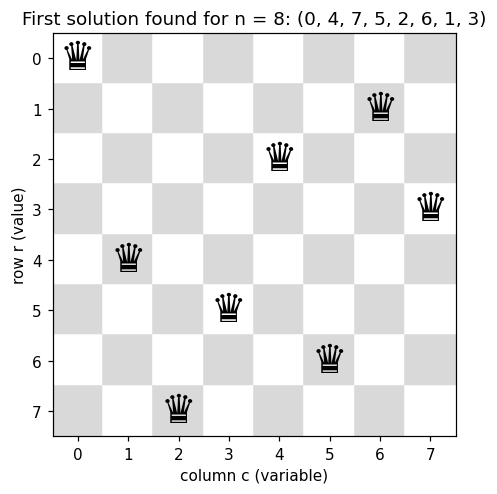

In [4]:
def board_text(sol):
    n = len(sol)
    return "\n".join(" ".join("Q" if sol[c] == r else "." for c in range(n)) for r in range(n))

first = sols_bt[0]
print("first solution found (row of queen per column):", first)
print(board_text(first))

fig, ax = plt.subplots(figsize=(4.6, 4.6))
n = len(first)
for r in range(n):
    for c in range(n):
        ax.add_patch(plt.Rectangle((c, r), 1, 1, color="0.85" if (r + c) % 2 else "white"))
for c, r in enumerate(first):
    ax.text(c + 0.5, r + 0.5, "♛", fontsize=26, ha="center", va="center")
ax.set(xlim=(0, n), ylim=(n, 0), aspect="equal", xlabel="column c (variable)", ylabel="row r (value)",
       title=f"First solution found for n = 8: {first}")
ax.set_xticks(np.arange(n) + 0.5); ax.set_xticklabels(range(n))
ax.set_yticks(np.arange(n) + 0.5); ax.set_yticklabels(range(n)); ax.grid(False)
fig.tight_layout(); save(fig, "fig2_1_board.png"); plt.show()

## 3. Scaling: n = 4 to 10, both methods

  n  solutions      nodes   backtrack    generate
  4          2         60     0.0000s     0.0000s
  5         10        220     0.0001s     0.0002s
  6          4        894     0.0004s     0.0018s
  7         40       3584     0.0015s     0.0158s
  8         92      15720     0.0065s     0.1562s
  9        352      72378     0.0326s     1.9172s
 10        724     348150     0.1881s    24.5141s
at n = 10 generate-and-test is 130x slower


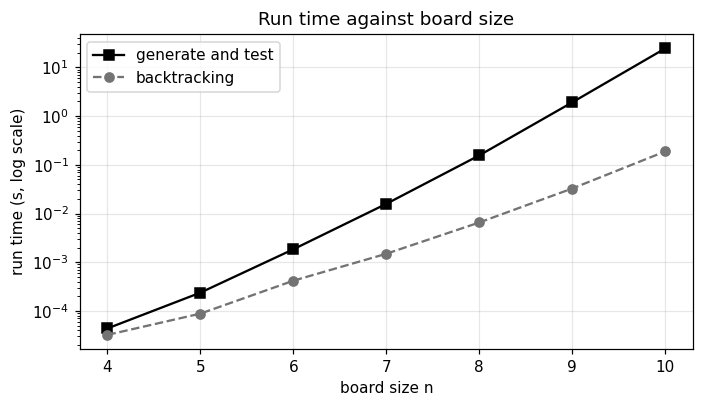

In [5]:
rows = []
print(f"{'n':>3} {'solutions':>10} {'nodes':>10} {'backtrack':>11} {'generate':>11}")
for n in range(4, 11):
    t0 = time.perf_counter(); s, nd = backtrack(n); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); g = generate_and_test(n); tg = time.perf_counter() - t0
    assert len(g) == len(s)                   # both methods must agree
    rows.append({"n": n, "solutions": len(s), "nodes": nd, "t_bt": tb, "t_gt": tg})
    print(f"{n:>3} {len(s):>10} {nd:>10} {tb:>10.4f}s {tg:>10.4f}s")
RESULTS["scaling"] = rows
RESULTS["ratio_n10"] = rows[-1]["t_gt"] / rows[-1]["t_bt"]
print(f"at n = 10 generate-and-test is {RESULTS['ratio_n10']:.0f}x slower")

ns = [r["n"] for r in rows]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogy(ns, [r["t_gt"] for r in rows], "s-", color="k", label="generate and test")
ax.semilogy(ns, [r["t_bt"] for r in rows], "o--", color="0.45", label="backtracking")
ax.set(xlabel="board size n", ylabel="run time (s, log scale)", title="Run time against board size")
ax.legend()
fig.tight_layout(); save(fig, "fig2_2_runtime.png"); plt.show()

## 4. Fundamental solutions under the 8 symmetries of the square

In [6]:
def transforms(sol):
    """All 8 images of a solution under rotations and reflections of the board."""
    n = len(sol)
    cells = [(r, c) for c, r in enumerate(sol)]
    ops = [lambda r, c: (r, c), lambda r, c: (c, n-1-r), lambda r, c: (n-1-r, n-1-c),
           lambda r, c: (n-1-c, r), lambda r, c: (r, n-1-c), lambda r, c: (n-1-r, c),
           lambda r, c: (c, r), lambda r, c: (n-1-c, n-1-r)]
    images = set()
    for op in ops:
        b = [0]*n
        for r, c in cells:
            rr, cc = op(r, c); b[cc] = rr
        images.add(tuple(b))
    return images

orbits, seen = [], set()
for s in sols_bt:
    if s not in seen:
        orb = transforms(s); seen |= orb; orbits.append(orb)
sizes = sorted(len(o) for o in orbits)
print(len(orbits), "fundamental solutions; orbit sizes:", sizes, "sum =", sum(sizes))
RESULTS["fundamental"] = {"count": len(orbits), "orbit_sizes": sizes}

12 fundamental solutions; orbit sizes: [4, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8] sum = 92


## 5. Bug check: what produces 2113 solutions?

In [7]:
def is_safe_buggy(board, col, row):
    """Diagonal test without abs on the row difference: only one diagonal direction is checked."""
    for c in range(col):
        if board[c] == row or board[c] - row == abs(c - col):
            return False
    return True

def count_with(safe, n=8):
    count = [0]
    def place(board, col):
        if col == n:
            count[0] += 1; return
        for row in range(n):
            if safe(board, col, row):
                board[col] = row; place(board, col + 1); board[col] = -1
    place([-1] * n, 0)
    return count[0]

RESULTS["buggy_count"] = count_with(is_safe_buggy)
print("solutions with the one-direction diagonal test:", RESULTS["buggy_count"])

solutions with the one-direction diagonal test: 2113


In [8]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved results.json and", len(os.listdir("figs")), "figures in figs/")

saved results.json and 2 figures in figs/
